# Percussive2 latent-space analysis — essentia perceptual features

Which perceptual properties of a percussive one-shot are **linearly encoded** in the VAE
latent (`percussive2_val_in_latent_space_nfv3`, 1511 clips × 256-d)? Labels are essentia
descriptors from `percussive2_val_labels.csv` (see `percussive2_val_labels.txt` for column
meanings): **92 continuous features** (envelope, brightness, timbre/MFCC, pitch/tonalness,
loudness) plus one categorical **`family`** (kick/snare/hat/clap/cymbal/unknown).

Structure:
1. **Coarse EDA** — feature distributions, `family` balance, latent active-dims, feature correlation blocks.
2. **Predictability sweep** — Ridge CV **R²** for every continuous feature, ranked. *This is the headline: which axes the latent captures.*
3. **Top-feature drilldown** — predicted-vs-true and which latent dims carry the best-predicted features.
4. **Family classification** — logistic CV on the named-family subset.

> **No speaker/group confound here.** Unlike the VCTK notebooks (where gender/accent leaked via speaker identity), these are independent one-shots, so plain **random K-fold CV is honest** — no grouping needed. The one caveat is `family` imbalance (see §0).

## 0 · Setup

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.ds_utils import load_audio_tensor

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_predict
from sklearn.metrics import (r2_score, mean_absolute_error, accuracy_score,
                             balanced_accuracy_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=FutureWarning)

# ---- config ----
LATENT_DIR = "/media/Data/jp_dir/sounds/percussive2_val_in_latent_space_nfv3"
LABELS_CSV = "/media/Data/jp_dir/sounds/percussive2_val_labels.csv"
LATENT_DIM   = 256
RANDOM_STATE = 0
N_SPLITS     = 5
rng = np.random.default_rng(RANDOM_STATE)

plt.rcParams.update({
    "figure.figsize": (8, 5), "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})

In [2]:
# load latents + labels, align strictly by filename (don't assume matching order)
enc = load_audio_tensor(LATENT_DIR)
Z_all = enc.data.detach().cpu().numpy().reshape(len(enc.filenames), -1).astype(np.float32)
assert Z_all.shape[1] == LATENT_DIM, Z_all.shape

labels = pd.read_csv(LABELS_CSV).set_index("filename")
order = [f for f in enc.filenames if f in labels.index]
assert len(order) == len(enc.filenames), "some latents have no label row"

# reorder Z to match labels lookup, build aligned frame
idx = {f: i for i, f in enumerate(enc.filenames)}
Z = Z_all[[idx[f] for f in order]]
meta = labels.loc[order].reset_index()

# continuous feature columns = everything except the two keys
FEATURES = [c for c in meta.columns if c not in ("filename", "family")]
FEATURES = [c for c in FEATURES if pd.api.types.is_numeric_dtype(meta[c])]
print(f"{len(meta)} clips | {len(FEATURES)} continuous features | latent {Z.shape}")
print("family counts:", meta.family.value_counts().to_dict())

1511 clips | 93 continuous features | latent (1511, 256)
family counts: {'unknown': 1134, 'snare': 177, 'kick': 146, 'hat': 32, 'clap': 11, 'cymbal': 11}


## 1 · Coarse EDA

### Latent: active dimensions & PCA spectrum
Same quick check as the VCTK notebooks — how many latent dims are actually used, and the effective dimensionality (covariance-PCA / RAVE-style fidelity).

active latent dims (var > 0.01): 256 / 256


  fidelity_0.8: 47 PCs
  fidelity_0.9: 85 PCs
  fidelity_0.95: 127 PCs
  fidelity_0.99: 205 PCs
  participation ratio (effective dims): 38.9


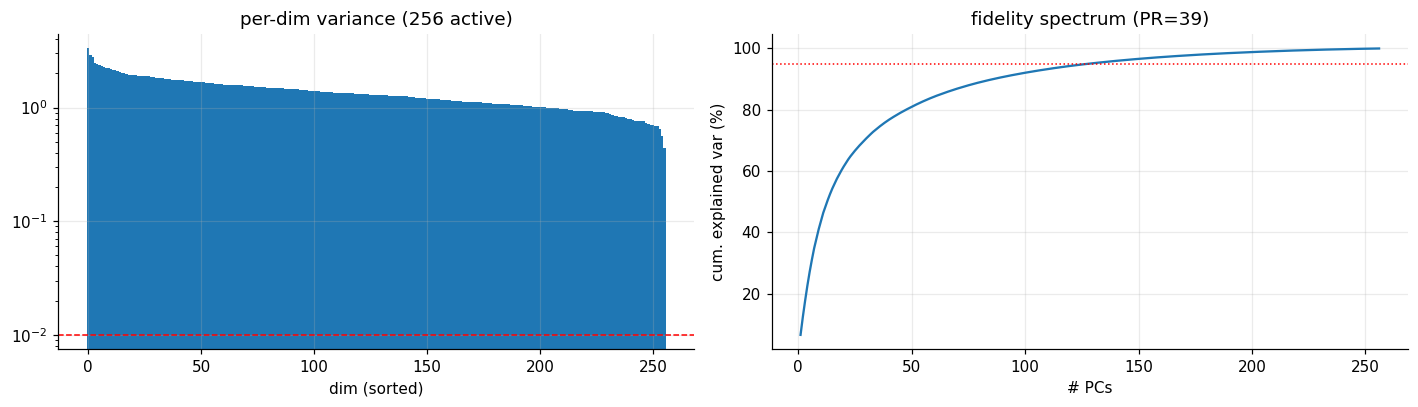

In [3]:
var = Z.var(0)
THR = 0.01
active = var > THR
print(f"active latent dims (var > {THR}): {active.sum()} / {LATENT_DIM}")

# covariance-PCA fidelity (RAVE-style): PCs to reach a variance fraction
pca_fid = PCA(LATENT_DIM, random_state=RANDOM_STATE).fit(Z - Z.mean(0))
fidelity = np.cumsum(pca_fid.explained_variance_ratio_)
pr = (pca_fid.explained_variance_.sum()**2) / (pca_fid.explained_variance_**2).sum()
for p in (.8, .9, .95, .99):
    print(f"  fidelity_{p}: {int(np.argmax(fidelity > p))} PCs")
print(f"  participation ratio (effective dims): {pr:.1f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].bar(range(LATENT_DIM), np.sort(var)[::-1], width=1.0)
ax[0].axhline(THR, color="r", ls="--", lw=1); ax[0].set_yscale("log")
ax[0].set_title(f"per-dim variance ({active.sum()} active)"); ax[0].set_xlabel("dim (sorted)")
ax[1].plot(np.arange(1, LATENT_DIM+1), fidelity*100)
ax[1].axhline(95, color="r", ls=":", lw=1); ax[1].set_title(f"fidelity spectrum (PR={pr:.0f})")
ax[1].set_xlabel("# PCs"); ax[1].set_ylabel("cum. explained var (%)")
plt.tight_layout(); plt.show()

### Feature distributions & family balance
Skim the target features. Many essentia descriptors are heavy-tailed / non-negative, so this is a coarse look (a subset of representative features); some may want log-scaling before regression, but Ridge on standardised inputs is robust to that for a first ranking.

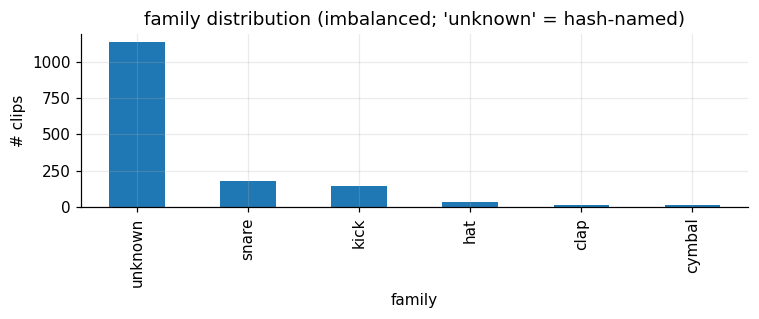

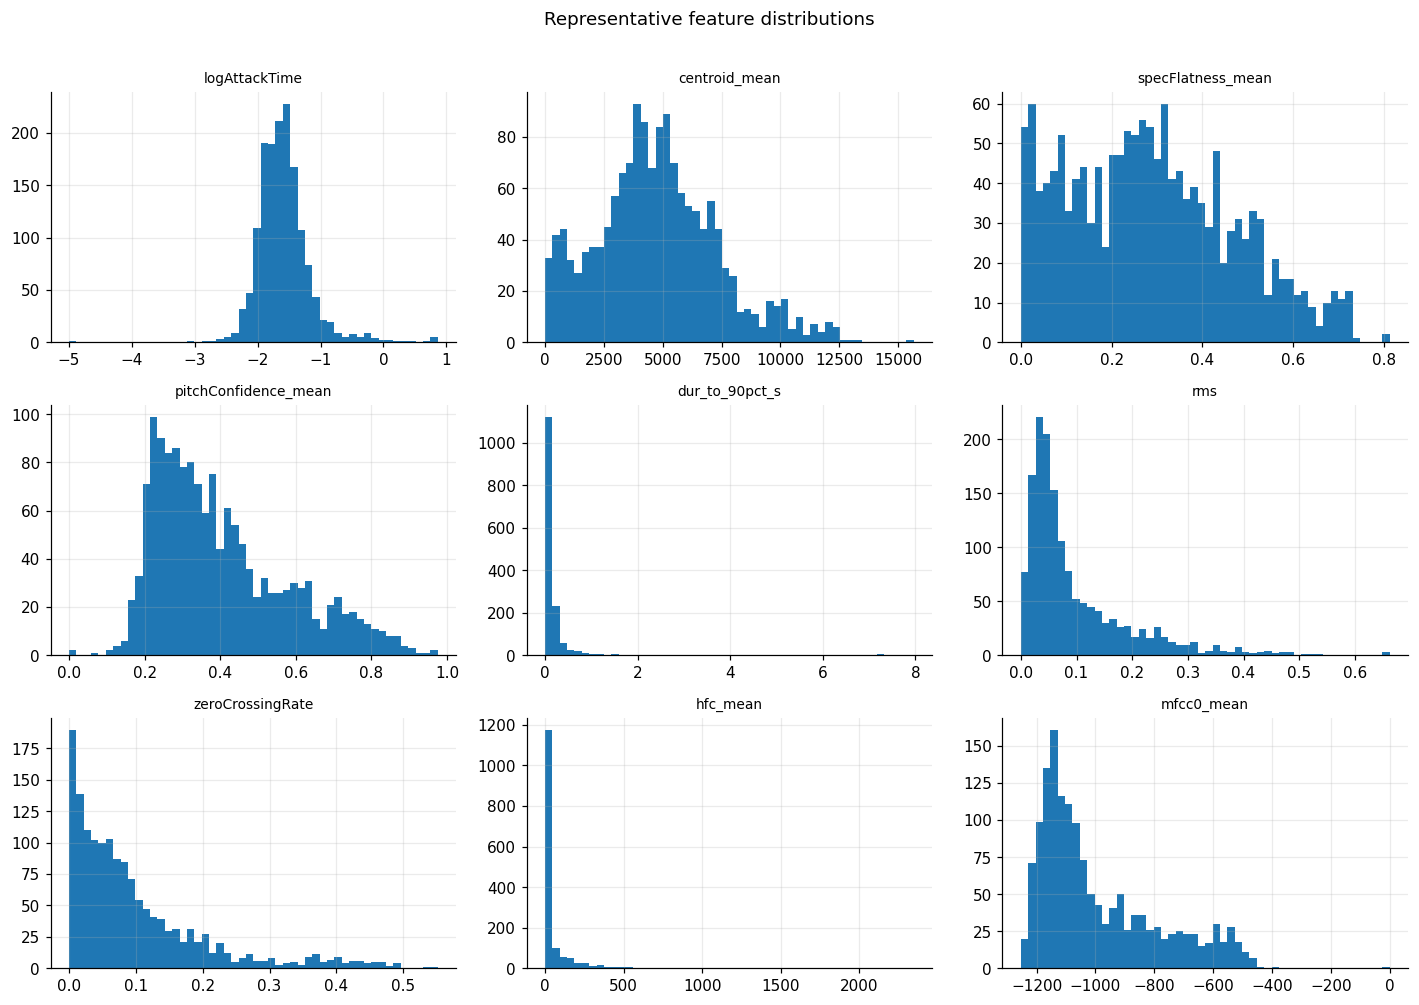

In [4]:
meta.family.value_counts().plot.bar(figsize=(7, 3))
plt.ylabel("# clips"); plt.title("family distribution (imbalanced; 'unknown' = hash-named)")
plt.tight_layout(); plt.show()

show = ["logAttackTime", "centroid_mean", "specFlatness_mean", "pitchConfidence_mean",
        "dur_to_90pct_s", "rms", "zeroCrossingRate", "hfc_mean", "mfcc0_mean"]
show = [c for c in show if c in FEATURES]
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for c, ax in zip(show, axes.ravel()):
    ax.hist(meta[c].to_numpy(), bins=50); ax.set_title(c, fontsize=9)
for ax in axes.ravel()[len(show):]:
    ax.set_visible(False)
plt.suptitle("Representative feature distributions", y=1.01); plt.tight_layout(); plt.show()

### Feature correlation structure
Many essentia features are redundant (e.g. brightness proxies co-vary). Blocks here mean groups of features carry the same information — so high R² for one implies high R² for its block.

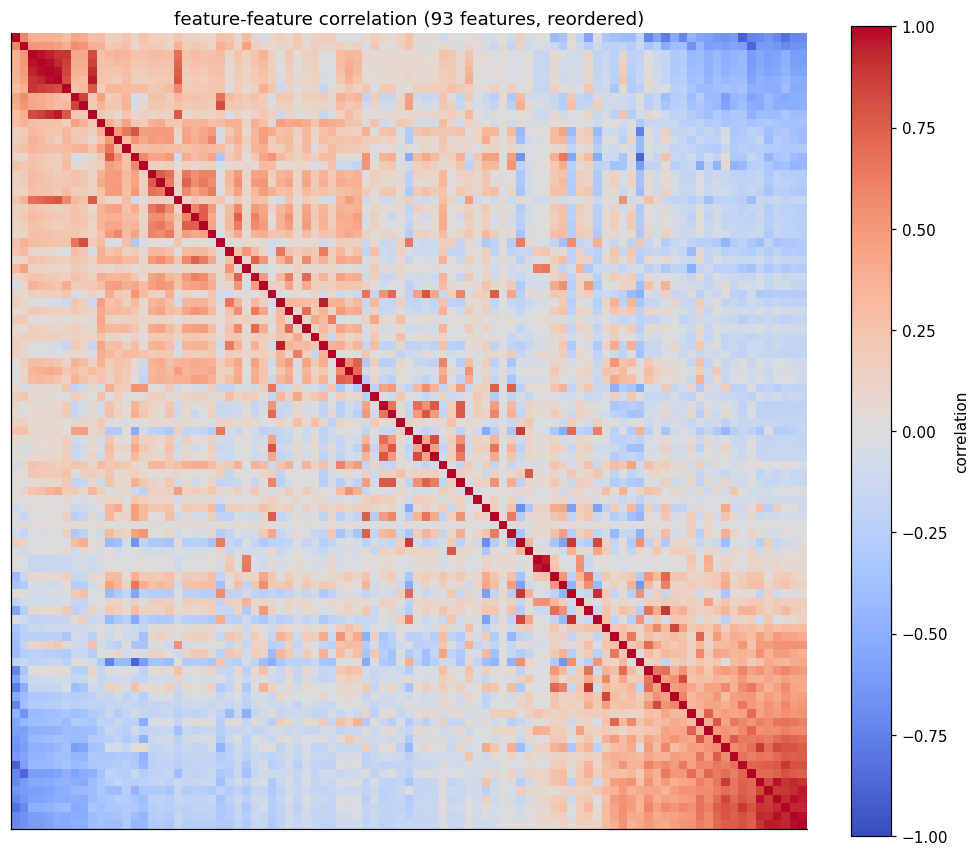

In [5]:
F = StandardScaler().fit_transform(meta[FEATURES].to_numpy())
C = np.corrcoef(F, rowvar=False)
# order by hierarchical-ish grouping via PCA angle for a readable block structure
ordr = np.argsort(PCA(2, random_state=RANDOM_STATE).fit(C).components_[0])
plt.figure(figsize=(9, 8))
plt.imshow(C[np.ix_(ordr, ordr)], vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar(label="correlation", fraction=0.046)
plt.title(f"feature-feature correlation ({len(FEATURES)} features, reordered)")
plt.xticks([]); plt.yticks([]); plt.tight_layout(); plt.show()

## 2 · Predictability sweep — which features are linearly decodable?

For **every** continuous feature: Ridge regression latent → feature, 5-fold CV, scored by **R²**
(and NRMSE for scale-free comparison). R² ≈ 1 means the latent linearly encodes that property;
R² ≈ 0 means it doesn't (or only non-linearly). This ranking is the main deliverable.

In [6]:
def cv_r2(y):
    reg = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    yhat = cross_val_predict(reg, Z, y, cv=KFold(N_SPLITS, shuffle=True,
                                                 random_state=RANDOM_STATE))
    return r2_score(y, yhat), yhat

rows, preds = [], {}
for c in FEATURES:
    y = meta[c].to_numpy(dtype=float)
    if np.std(y) < 1e-9:               # constant feature -> R2 undefined
        rows.append((c, np.nan, np.nan)); continue
    r2, yhat = cv_r2(y)
    nrmse = np.sqrt(np.mean((y - yhat)**2)) / (np.std(y) + 1e-12)
    rows.append((c, r2, nrmse)); preds[c] = yhat

rank = (pd.DataFrame(rows, columns=["feature", "r2", "nrmse"])
        .dropna().sort_values("r2", ascending=False).reset_index(drop=True))
print("most linearly predictable:")
print(rank.head(15).to_string(index=False))
print("\nleast linearly predictable:")
print(rank.tail(10).to_string(index=False))

most linearly predictable:
            feature       r2    nrmse
        strongDecay 0.851059 0.385929
                rms 0.776135 0.473144
           loudness 0.706810 0.541470
   specDecrease_std 0.691581 0.555350
  specDecrease_mean 0.660914 0.582308
specComplexity_mean 0.609625 0.624800
 specComplexity_std 0.601932 0.630926
     specCrest_mean 0.589655 0.640582
         mfcc2_mean 0.560449 0.662987
            hfc_std 0.550799 0.670224
         mfcc0_mean 0.536825 0.680570
         mfcc1_mean 0.516775 0.695144
           hfc_mean 0.498780 0.707969
    loudnessVickers 0.490855 0.713544
          TCToTotal 0.481780 0.719875

least linearly predictable:
       feature        r2    nrmse
    mfcc11_std -0.065410 1.032187
dur_to_90pct_s -0.074239 1.036455
    dissonance -0.075248 1.036942
 contrast5_std -0.076500 1.037545
  tristimulus1 -0.106617 1.051959
    pitch_mean -0.106746 1.052020
     pitch_std -0.154784 1.074609
     oddToEven -0.243186 1.114982
 inharmonicity -0.256805 1.121

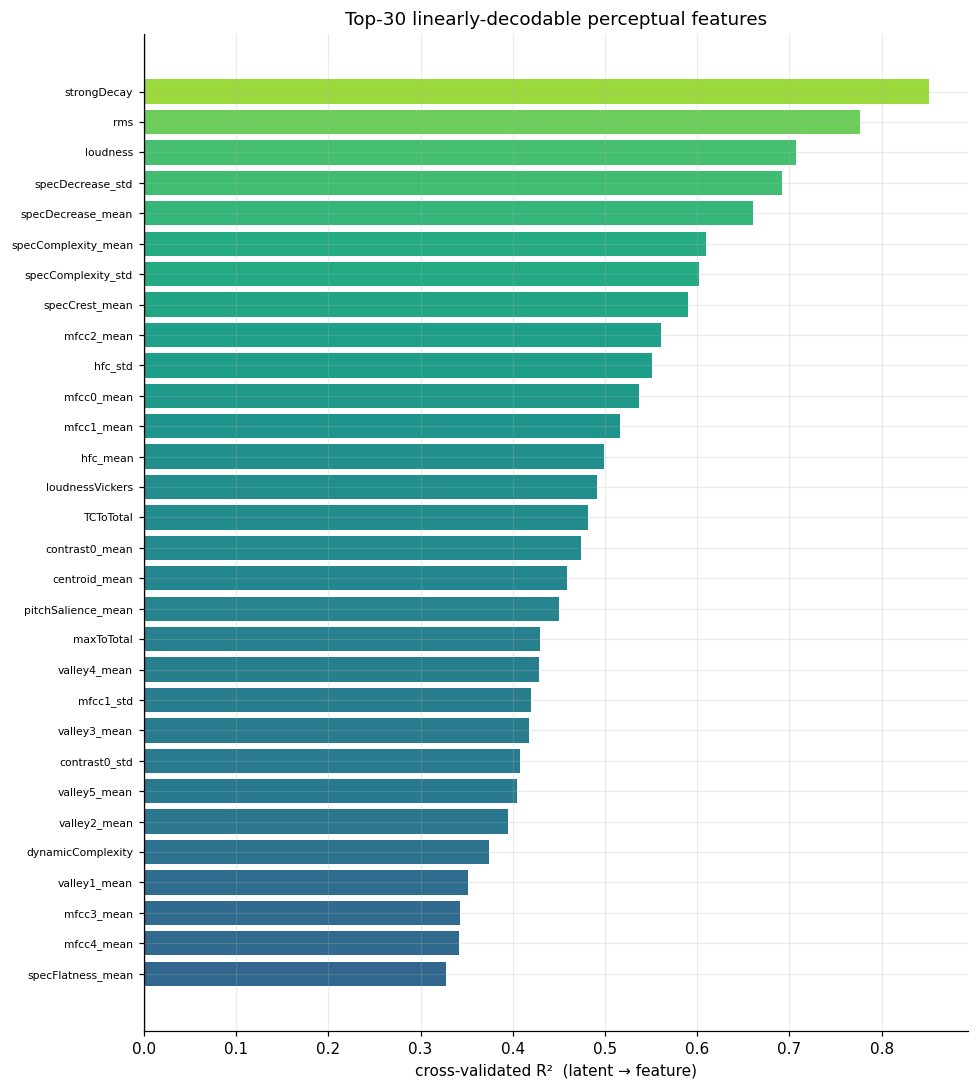

In [7]:
top = rank.head(30)[::-1]
plt.figure(figsize=(9, 10))
colors = plt.get_cmap("viridis")(np.clip(top.r2, 0, 1))
plt.barh(range(len(top)), top.r2, color=colors)
plt.yticks(range(len(top)), top.feature, fontsize=7)
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("cross-validated R²  (latent → feature)")
plt.title("Top-30 linearly-decodable perceptual features"); plt.tight_layout(); plt.show()

## 3 · Top-feature drilldown
Predicted-vs-true for the best-predicted features, and — for the single best — which latent dims carry it (|correlation| with the feature).

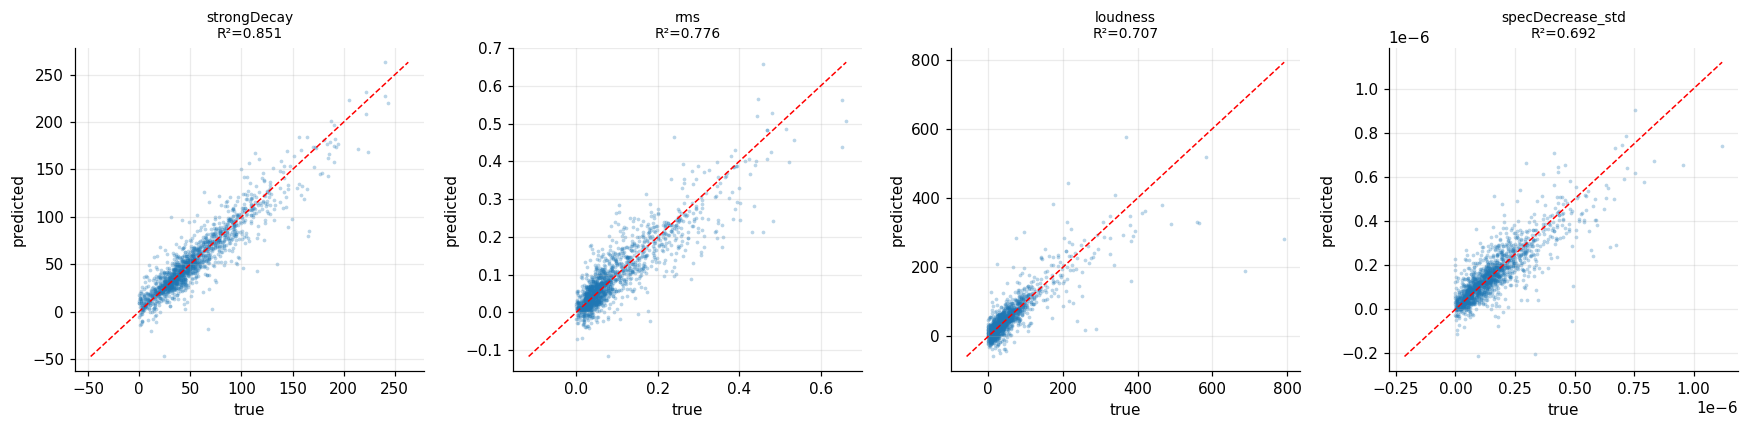

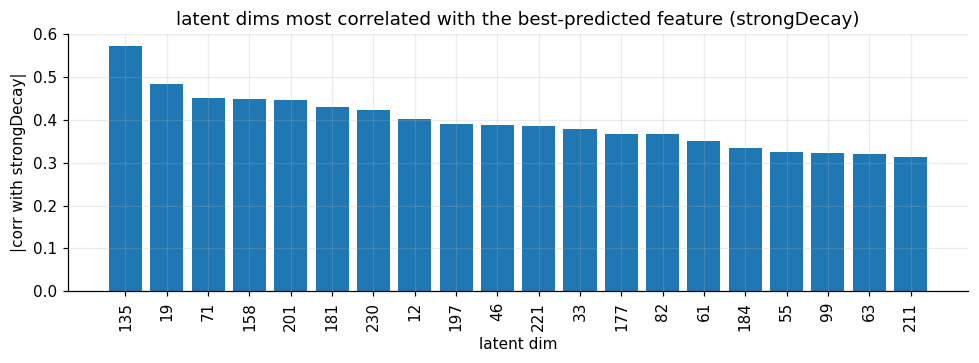

In [8]:
best = rank.head(4).feature.tolist()
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for c, ax in zip(best, axes):
    y = meta[c].to_numpy(dtype=float); yh = preds[c]
    ax.scatter(y, yh, s=6, alpha=0.3, linewidths=0)
    lim = [min(y.min(), yh.min()), max(y.max(), yh.max())]
    ax.plot(lim, lim, "r--", lw=1)
    ax.set_title(f"{c}\nR²={rank.set_index('feature').r2[c]:.3f}", fontsize=9)
    ax.set_xlabel("true"); ax.set_ylabel("predicted")
plt.tight_layout(); plt.show()

# which latent dims carry the single best feature
c0 = best[0]; y = meta[c0].to_numpy(dtype=float)
yc = y - y.mean(); Zc = Z - Z.mean(0)
corr = (Zc * yc[:, None]).sum(0) / (np.linalg.norm(Zc, axis=0) * np.linalg.norm(yc) + 1e-12)
topd = np.argsort(np.abs(corr))[::-1][:20]
plt.figure(figsize=(9, 3.4))
plt.bar(range(20), np.abs(corr)[topd]); plt.xticks(range(20), topd, rotation=90)
plt.xlabel("latent dim"); plt.ylabel(f"|corr with {c0}|")
plt.title(f"latent dims most correlated with the best-predicted feature ({c0})")
plt.tight_layout(); plt.show()

## 4 · Family classification (named subset)

`family` is the only categorical label, and heavily imbalanced (`unknown` dominates and is
hash-named/ambiguous per the description). We **drop `unknown`** and classify the named
families. Note clap/cymbal have very few samples (~11) — read **balanced accuracy** and the
per-class report, not raw accuracy, and treat the tiny classes as indicative only.

named-family counts: {'snare': 177, 'kick': 146, 'hat': 32, 'clap': 11, 'cymbal': 11}



family — random 5-fold (no group confound):
  accuracy      0.947
  balanced acc  0.874
  chance        0.200 uniform / 0.379 by-frequency

              precision    recall  f1-score   support

        clap       0.56      0.45      0.50        11
      cymbal       0.92      1.00      0.96        11
         hat       0.97      1.00      0.98        32
        kick       0.97      0.96      0.96       146
       snare       0.95      0.95      0.95       177

    accuracy                           0.95       377
   macro avg       0.87      0.87      0.87       377
weighted avg       0.94      0.95      0.95       377



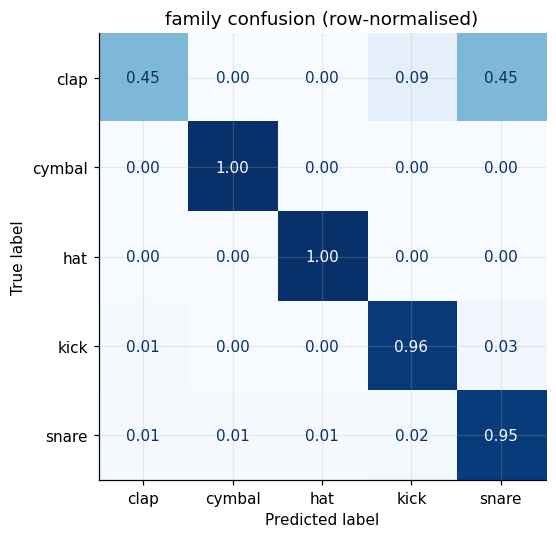

In [9]:
named = meta.family != "unknown"
Zf = Z[named.to_numpy()]
fam = meta.loc[named, "family"].to_numpy()
le = LabelEncoder().fit(fam); yf = le.transform(fam)
counts = pd.Series(fam).value_counts()
print("named-family counts:", counts.to_dict())

# folds bounded by the rarest class so stratified CV is valid
ns = max(2, min(N_SPLITS, int(counts.min())))
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
yhat = cross_val_predict(clf, Zf, yf, cv=StratifiedKFold(ns, shuffle=True,
                                                          random_state=RANDOM_STATE))
freq = pd.Series(yf).value_counts(normalize=True)
print(f"\nfamily — random {ns}-fold (no group confound):")
print(f"  accuracy      {accuracy_score(yf, yhat):.3f}")
print(f"  balanced acc  {balanced_accuracy_score(yf, yhat):.3f}")
print(f"  chance        {1/len(le.classes_):.3f} uniform / {(freq**2).sum():.3f} by-frequency\n")
print(classification_report(yf, yhat, target_names=le.classes_, zero_division=0))

cm = confusion_matrix(yf, yhat, normalize="true")
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(ax=ax, cmap="Blues",
                                                            colorbar=False, values_format=".2f")
plt.title("family confusion (row-normalised)"); plt.tight_layout(); plt.show()

### Unsupervised clustering vs. `family`

Do the named families form *clusters* in the latent (unsupervised), or is `family` only
recoverable by a supervised boundary (§4)? We cluster the named-family latents with three
methods — **KMeans**, **Agglomerative (Ward)**, and **Gaussian Mixture** — at k = number of
families, and score each two ways:

* **Silhouette** — geometric cohesion/separation of the *discovered* clusters (label-free; higher = tighter, better-separated clusters).
* **ARI / NMI** — agreement between discovered clusters and the true `family` labels (do the clusters *correspond* to families?).

We also report the **silhouette of the true family labels** as the reference: if supervised
accuracy (§4) is high but this is ~0, families are linearly separable but not compact blobs
(the pattern seen for gender in the VCTK notebooks).

clustering 377 named-family latents into k=5 clusters

method          silhouette     ARI     NMI


KMeans               0.121   0.564   0.607
Agglomerative        0.078   0.378   0.498
GaussianMix          0.070   0.210   0.334

silhouette of TRUE family labels: +0.066  (reference: are families compact blobs?)
ARI/NMI ~1 => discovered clusters match families; silhouette compares cohesion.


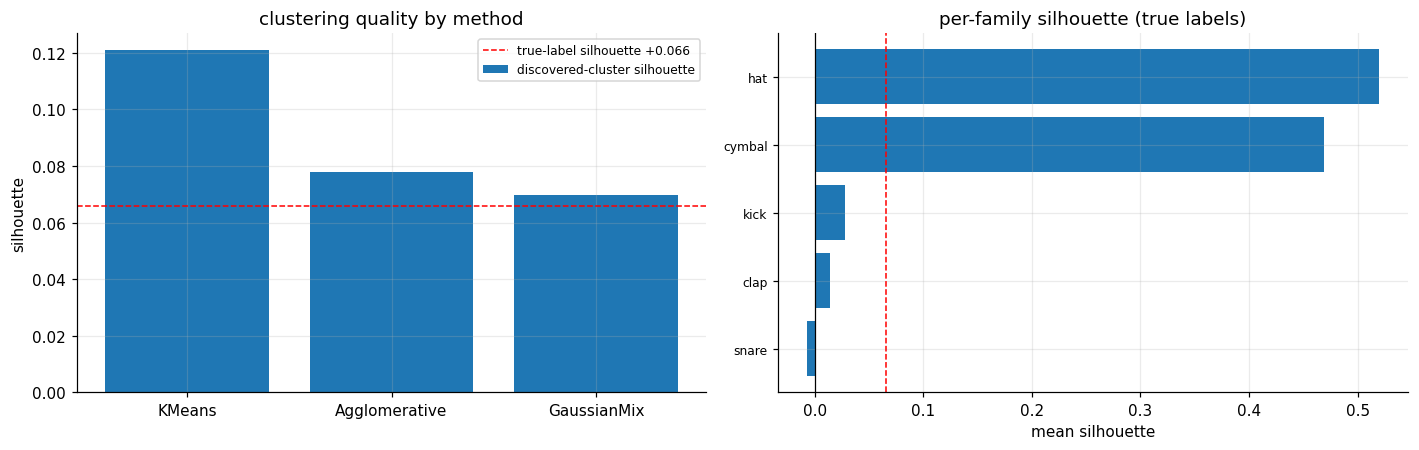

In [10]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, adjusted_rand_score,
                             normalized_mutual_info_score, silhouette_samples)

Zfs = StandardScaler().fit_transform(Zf).astype(np.float64)      # named-family latents, standardised
k = len(le.classes_)

methods = {
    "KMeans":        KMeans(k, n_init=10, random_state=RANDOM_STATE),
    "Agglomerative": AgglomerativeClustering(k),
    "GaussianMix":   GaussianMixture(k, covariance_type="diag", reg_covar=1e-4, random_state=RANDOM_STATE),
}
print(f"clustering {len(Zfs)} named-family latents into k={k} clusters\n")
print(f"{'method':14s} {'silhouette':>11s} {'ARI':>7s} {'NMI':>7s}")
rows = []
for name, m in methods.items():
    cl = m.fit_predict(Zfs)
    sil = silhouette_score(Zfs, cl)
    ari = adjusted_rand_score(yf, cl)
    nmi = normalized_mutual_info_score(yf, cl)
    rows.append((name, sil, ari, nmi))
    print(f"{name:14s} {sil:11.3f} {ari:7.3f} {nmi:7.3f}")

sil_true = silhouette_score(Zfs, yf)
print(f"\nsilhouette of TRUE family labels: {sil_true:+.3f}  "
      "(reference: are families compact blobs?)")
print("ARI/NMI ~1 => discovered clusters match families; silhouette compares cohesion.")

# per-family silhouette under the true labels
samp = silhouette_samples(Zfs, yf)
order = np.argsort([samp[yf == i].mean() for i in range(k)])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].bar([m[0] for m in rows], [m[1] for m in rows], label="discovered-cluster silhouette")
ax[0].axhline(sil_true, color="r", ls="--", lw=1, label=f"true-label silhouette {sil_true:+.3f}")
ax[0].set_ylabel("silhouette"); ax[0].set_title("clustering quality by method"); ax[0].legend(fontsize=8)
ax[1].barh(range(k), [samp[yf == i].mean() for i in order])
ax[1].set_yticks(range(k)); ax[1].set_yticklabels([le.classes_[i] for i in order], fontsize=8)
ax[1].axvline(0, color="k", lw=0.8); ax[1].axvline(sil_true, color="r", ls="--", lw=1)
ax[1].set_xlabel("mean silhouette"); ax[1].set_title("per-family silhouette (true labels)")
plt.tight_layout(); plt.show()

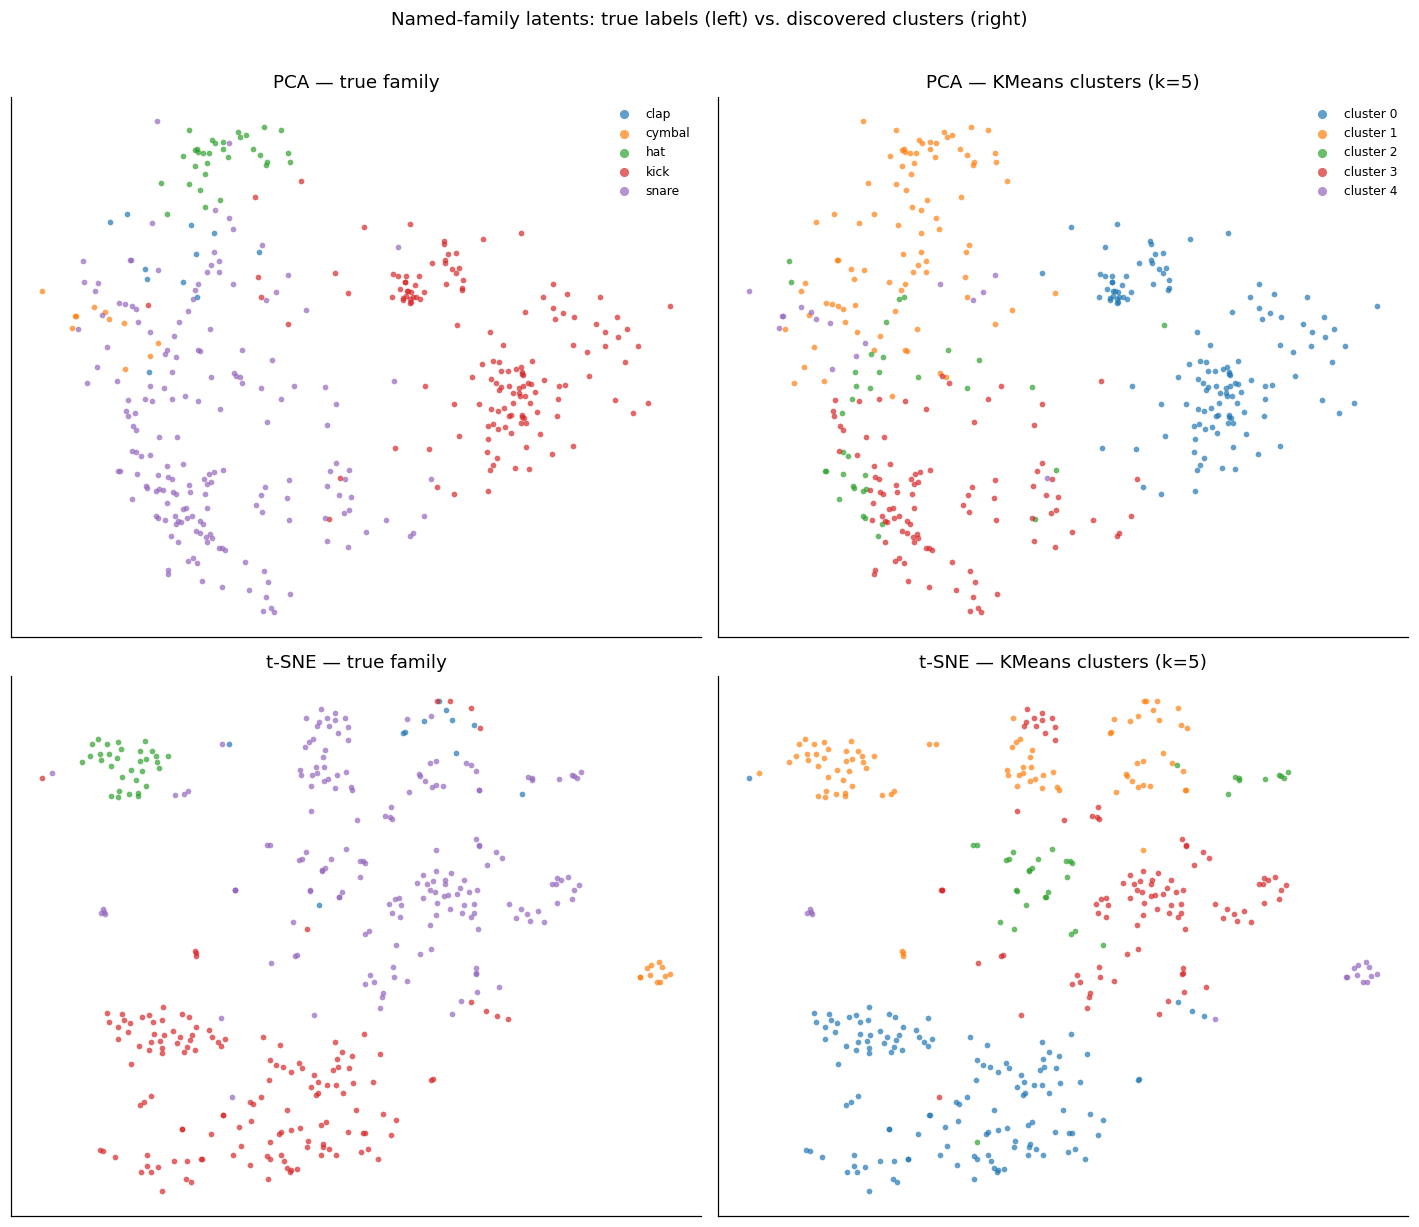

In [11]:
# --- draw the family clusters: PCA + t-SNE, true families vs. KMeans clusters ---
from sklearn.manifold import TSNE

emb = {
    "PCA":   PCA(2, random_state=RANDOM_STATE).fit_transform(Zfs),
    "t-SNE": TSNE(2, init="pca", perplexity=30, random_state=RANDOM_STATE).fit_transform(Zfs),
}
km_lab = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(Zfs)  # best method (§4)

fam_cats = list(le.classes_)
cmap_fam = plt.get_cmap("tab10")

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for row, (name, XY) in enumerate(emb.items()):
    # left: coloured by TRUE family
    ax = axes[row, 0]
    for ci, fam in enumerate(fam_cats):
        m = yf == ci
        ax.scatter(XY[m, 0], XY[m, 1], s=14, alpha=0.7, linewidths=0,
                   color=cmap_fam(ci), label=fam)
    ax.set_title(f"{name} — true family"); ax.set_xticks([]); ax.set_yticks([])
    if row == 0:
        ax.legend(markerscale=1.6, fontsize=8, frameon=False, loc="best")
    # right: coloured by KMeans discovered cluster
    ax = axes[row, 1]
    for cl in range(k):
        m = km_lab == cl
        ax.scatter(XY[m, 0], XY[m, 1], s=14, alpha=0.7, linewidths=0, label=f"cluster {cl}")
    ax.set_title(f"{name} — KMeans clusters (k={k})"); ax.set_xticks([]); ax.set_yticks([])
    if row == 0:
        ax.legend(markerscale=1.6, fontsize=8, frameon=False, loc="best")
plt.suptitle("Named-family latents: true labels (left) vs. discovered clusters (right)", y=1.01)
plt.tight_layout(); plt.show()

## 4.5 · Do the top features live in the high-fidelity directions?

Same question as the VCTK notebooks, for the 4 best-predicted features (§2): is each feature's
signal carried by the **high-energy** covariance-PCA directions (the ones fidelity §1 counts
first), or spread across low-variance directions? Two views against the covariance-PCA basis:

* **Cumulative R²** — Ridge R² for the feature using only the first *k* energy-ordered PCA
  directions, overlaid on the fidelity variance curve. Saturating early ⇒ the feature rides
  the high-fidelity subspace; a long climb ⇒ it draws on low-energy directions.
* **Per-PC alignment** — |correlation| between each feature and each leading PCA score,
  showing *which* energy-ranked directions carry it.

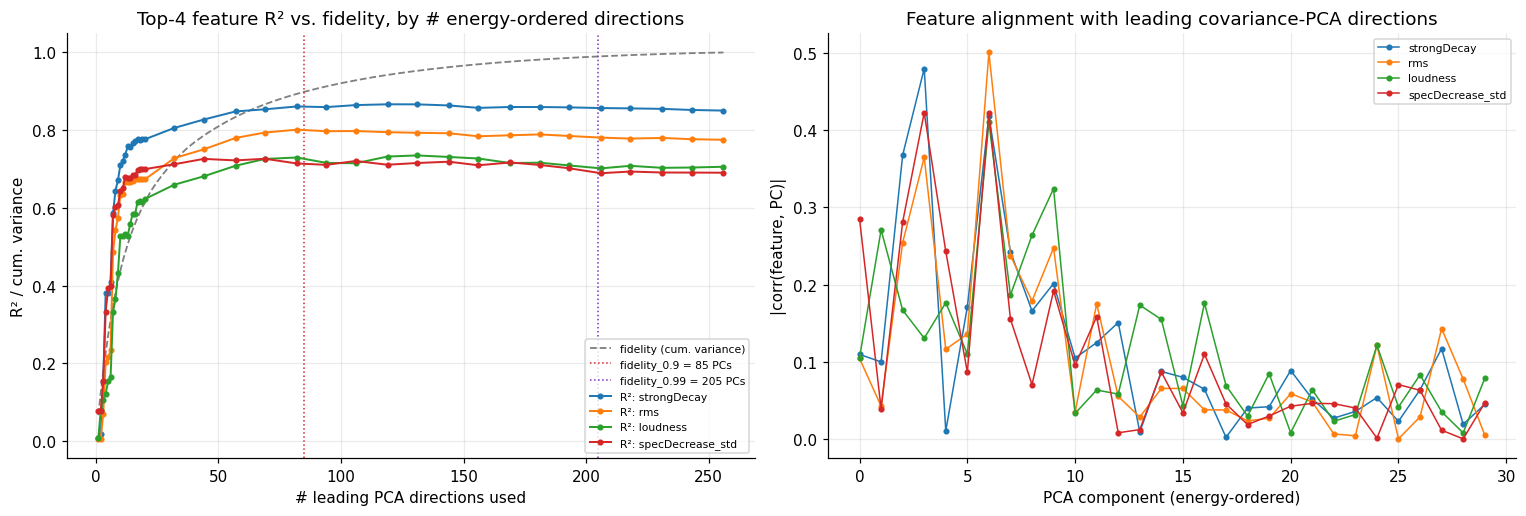

PCs needed to reach 90% of the feature's full-latent R²:


  strongDecay          full R²=0.851  ->  90% at 16 PCs (fidelity_0.9 = 85 PCs)


  rms                  full R²=0.776  ->  90% at 32 PCs (fidelity_0.9 = 85 PCs)


  loudness             full R²=0.707  ->  90% at 32 PCs (fidelity_0.9 = 85 PCs)


  specDecrease_std     full R²=0.692  ->  90% at 10 PCs (fidelity_0.9 = 85 PCs)


In [12]:
from sklearn.model_selection import cross_val_predict, KFold

# covariance-PCA basis on the full latent (same recipe as §1)
pca_b = PCA(LATENT_DIM, random_state=RANDOM_STATE).fit(Z - Z.mean(0))
comps = pca_b.components_
evr_cum = np.cumsum(pca_b.explained_variance_ratio_)
Zp = (Z - Z.mean(0)) @ comps.T               # latents in energy-ordered PCA coords

best4 = rank.head(4).feature.tolist()
ks = np.unique(np.clip(np.r_[np.arange(1, 21),
               np.linspace(20, LATENT_DIM, 20).astype(int)], 1, LATENT_DIM))
cv = KFold(N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].plot(np.arange(1, LATENT_DIM + 1), evr_cum, color="gray", ls="--", lw=1.2,
           label="fidelity (cum. variance)")
for p, col in [(.9, "#d62728"), (.99, "#7f2fbf")]:
    kf = int(np.argmax(evr_cum > p))
    ax[0].axvline(kf, color=col, ls=":", lw=1, label=f"fidelity_{p} = {kf} PCs")

cmap = plt.get_cmap("tab10")
for j, feat in enumerate(best4):
    y = meta[feat].to_numpy(dtype=float)
    r2s = []
    for kk in ks:
        yhat = cross_val_predict(make_pipeline(StandardScaler(), Ridge(1.0)),
                                 Zp[:, :kk], y, cv=cv)
        r2s.append(r2_score(y, yhat))
    ax[0].plot(ks, r2s, "o-", ms=3, lw=1.3, color=cmap(j), label=f"R²: {feat}")
    # per-PC alignment
    yc = y - y.mean()
    corr = (Zp * yc[:, None]).sum(0) / (np.linalg.norm(Zp, axis=0) * np.linalg.norm(yc) + 1e-12)
    ax[1].plot(range(30), np.abs(corr)[:30], "o-", ms=3, lw=1, color=cmap(j), label=feat)

ax[0].set_xlabel("# leading PCA directions used"); ax[0].set_ylabel("R² / cum. variance")
ax[0].set_title("Top-4 feature R² vs. fidelity, by # energy-ordered directions")
ax[0].legend(fontsize=7, loc="lower right")
ax[1].set_xlabel("PCA component (energy-ordered)"); ax[1].set_ylabel("|corr(feature, PC)|")
ax[1].set_title("Feature alignment with leading covariance-PCA directions")
ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

# summary: for each feature, the PC index reaching 90% of full-latent R²
print("PCs needed to reach 90% of the feature's full-latent R²:")
for feat in best4:
    y = meta[feat].to_numpy(dtype=float)
    full = rank.set_index("feature").r2[feat]
    hit = None
    for kk in ks:
        yhat = cross_val_predict(make_pipeline(StandardScaler(), Ridge(1.0)), Zp[:, :kk], y, cv=cv)
        if r2_score(y, yhat) >= 0.9 * full:
            hit = int(kk); break
    print(f"  {feat:20s} full R²={full:.3f}  ->  90% at {hit} PCs "
          f"(fidelity_0.9 = {int(np.argmax(evr_cum > 0.9))} PCs)")

## 5 · How to read the results

* **§1** — effective latent size (active dims / participation ratio) bounds what *any* probe can recover; the feature correlation blocks mean redundant features will share R² ranks.
* **§2** — the ranking is the headline. High-R² features are the perceptual axes the latent linearly encodes; expect envelope/brightness/loudness proxies (centroid, hfc, zero-crossing, rms, mfcc0, duration) near the top and fragile pitch/harmonic descriptors (only defined on pitched frames) near the bottom.
* **§3** — a high R² with a *tight* predicted-vs-true diagonal is a genuinely well-encoded axis; a high R² driven by a few outliers is not. The dim-importance bar shows whether a feature rides one latent direction or many.
* **§4** — family is a coarse sanity check; kick/snare/hat should separate well (distinct spectra), clap/cymbal are under-sampled. Balanced accuracy vs. the by-frequency baseline is the number to trust.

**Knobs:** `Ridge(alpha)` (regularisation strength for the sweep), `THR` (active-dim cutoff), and dropping/log-scaling heavy-tailed features before §2 if you want a stricter ranking.

## 6 · Train vs. validation — does the encoder generalise?

Everything above is on the **val** set. Here we repeat the two probes on **train**
(`percussive2_train_in_latent_space_nfv3`, 13452 clips) and compare. The question is *not*
whether the linear probe overfits — CV handles that on each set independently — but whether
the **encoder's feature→latent relationship is the same on data it trained on vs. held-out
data**:

* **Small train↔val gap** ⇒ the latent encodes perceptual structure that *generalises*; the
  val findings above are trustworthy properties of the encoder, not artefacts.
* **Large train ≫ val gap** ⇒ the encoder captured train-specific structure that doesn't
  transfer (memorisation) — the per-feature R² would then be optimistic on train.

Train also has far more clap/cymbal samples (122/130 vs. 11/11), so the family classifier is
more reliable there — a second, independent generalisation check.

In [13]:
# --- load train latents + labels, aligned by filename (mirrors §0) ---
TRAIN_LATENT_DIR = "/media/Data/jp_dir/sounds/percussive2_train_in_latent_space_nfv3"
TRAIN_LABELS_CSV = "/media/Data/jp_dir/sounds/percussive2_train_labels.csv"

enc_tr = load_audio_tensor(TRAIN_LATENT_DIR)
Ztr_all = enc_tr.data.detach().cpu().numpy().reshape(len(enc_tr.filenames), -1).astype(np.float32)
lab_tr = pd.read_csv(TRAIN_LABELS_CSV).set_index("filename")
order_tr = [f for f in enc_tr.filenames if f in lab_tr.index]
assert len(order_tr) == len(enc_tr.filenames)
idx_tr = {f: i for i, f in enumerate(enc_tr.filenames)}
Ztr = Ztr_all[[idx_tr[f] for f in order_tr]]
meta_tr = lab_tr.loc[order_tr].reset_index()
assert list(meta_tr.columns) == list(meta.columns), "train/val column mismatch"
print(f"train: {len(meta_tr)} clips | latent {Ztr.shape}")
print("train family:", meta_tr.family.value_counts().to_dict())

# --- same Ridge CV R2 sweep on TRAIN ---
def cv_r2_on(X, y):
    reg = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    yhat = cross_val_predict(reg, X, y, cv=KFold(N_SPLITS, shuffle=True,
                                                 random_state=RANDOM_STATE))
    return r2_score(y, yhat)

r2_tr = {}
for c in FEATURES:
    y = meta_tr[c].to_numpy(dtype=float)
    r2_tr[c] = np.nan if np.std(y) < 1e-9 else cv_r2_on(Ztr, y)

val_r2 = rank.set_index("feature").r2          # from §2
cmp = pd.DataFrame({"val_r2": val_r2}).join(pd.Series(r2_tr, name="train_r2")).dropna()
cmp["gap"] = cmp["train_r2"] - cmp["val_r2"]
print(f"\nfeatures compared: {len(cmp)}")
print(f"mean val R²   = {cmp.val_r2.mean():.3f}")
print(f"mean train R² = {cmp.train_r2.mean():.3f}")
print(f"mean gap (train - val) = {cmp.gap.mean():+.3f}  "
      "(≈0 => encoder generalises; large + => train-specific structure)")
print("\nlargest train-over-val gaps (potential overfit):")
print(cmp.sort_values('gap', ascending=False).head(6)[['val_r2','train_r2','gap']].to_string())

train: 13452 clips | latent (13452, 256)
train family: {'unknown': 9816, 'snare': 1679, 'kick': 1383, 'hat': 322, 'cymbal': 130, 'clap': 122}



features compared: 93
mean val R²   = 0.231
mean train R² = 0.463
mean gap (train - val) = +0.231  (≈0 => encoder generalises; large + => train-specific structure)

largest train-over-val gaps (potential overfit):
                  val_r2  train_r2       gap
feature                                     
flatnessSFX    -0.819642 -0.058317  0.761325
dur_to_90pct_s -0.074239  0.370036  0.444274
dur_to_50pct_s -0.032724  0.362397  0.395121
mfcc5_mean      0.115979  0.480747  0.364768
contrast5_std  -0.076500  0.269080  0.345581
inharmonicity  -0.256805  0.082063  0.338868


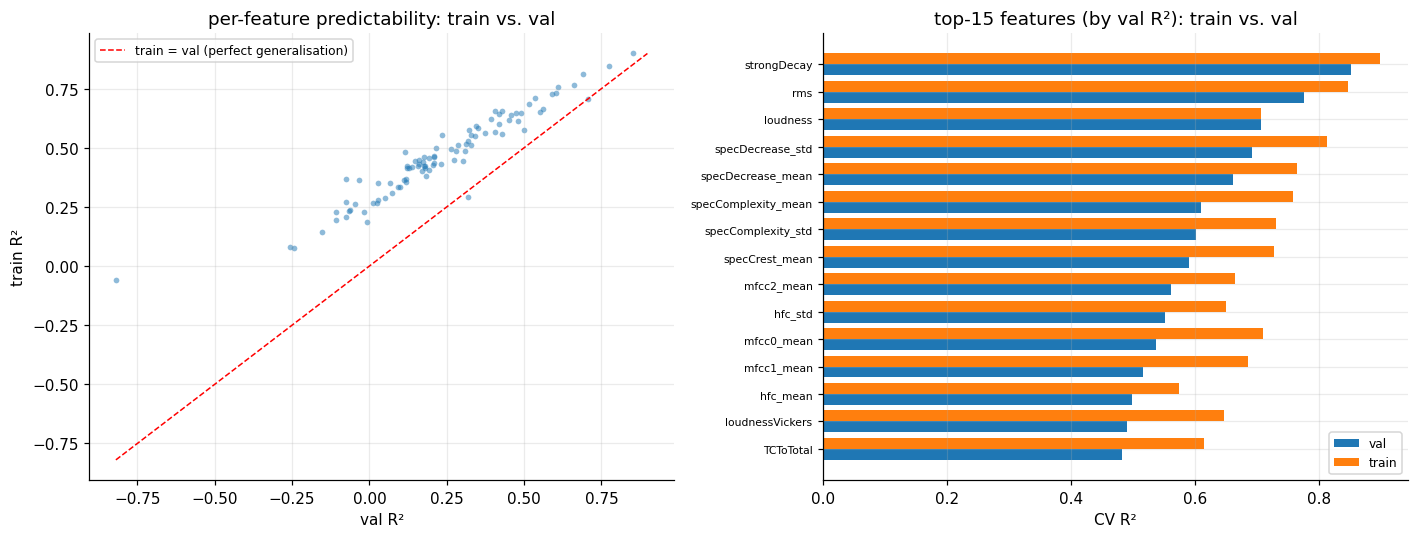

In [14]:
# --- overlay: train R2 vs val R2 per feature ---
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(cmp.val_r2, cmp.train_r2, s=14, alpha=0.5, linewidths=0)
lim = [min(cmp.val_r2.min(), cmp.train_r2.min()), max(cmp.val_r2.max(), cmp.train_r2.max())]
ax[0].plot(lim, lim, "r--", lw=1, label="train = val (perfect generalisation)")
ax[0].set_xlabel("val R²"); ax[0].set_ylabel("train R²")
ax[0].set_title("per-feature predictability: train vs. val"); ax[0].legend(fontsize=8)

# top features side-by-side bars (val ranking)
topf = rank.head(15).feature.tolist()[::-1]
yv = [val_r2[f] for f in topf]; yt = [r2_tr[f] for f in topf]
yy = np.arange(len(topf))
ax[1].barh(yy - 0.2, yv, height=0.4, label="val")
ax[1].barh(yy + 0.2, yt, height=0.4, label="train")
ax[1].set_yticks(yy); ax[1].set_yticklabels(topf, fontsize=7)
ax[1].set_xlabel("CV R²"); ax[1].set_title("top-15 features (by val R²): train vs. val")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [15]:
# --- family classification on train (same recipe as §4) ---
named_tr = meta_tr.family != "unknown"
Zftr = Ztr[named_tr.to_numpy()]
fam_tr = meta_tr.loc[named_tr, "family"].to_numpy()
le_tr = LabelEncoder().fit(fam_tr); yftr = le_tr.transform(fam_tr)
counts_tr = pd.Series(fam_tr).value_counts()
ns_tr = max(2, min(N_SPLITS, int(counts_tr.min())))
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
yhat_tr = cross_val_predict(clf, Zftr, yftr,
                            cv=StratifiedKFold(ns_tr, shuffle=True, random_state=RANDOM_STATE))
# recompute val family predictions locally (the notebook-level yhat may be reused elsewhere)
yhat_va = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
                            Zf, yf, cv=StratifiedKFold(max(2, min(N_SPLITS, int(pd.Series(yf).value_counts().min()))),
                            shuffle=True, random_state=RANDOM_STATE))
print("family classification balanced accuracy:")
print(f"  val   : {balanced_accuracy_score(yf, yhat_va):.3f}  (n={len(yf)}, clap/cymbal ~11 each)")
print(f"  train : {balanced_accuracy_score(yftr, yhat_tr):.3f}  (n={len(yftr)}, clap/cymbal >100)")
print("\ntrain per-class (more reliable — larger tiny classes):")
print(classification_report(yftr, yhat_tr, target_names=le_tr.classes_, zero_division=0))

family classification balanced accuracy:
  val   : 0.874  (n=377, clap/cymbal ~11 each)
  train : 0.934  (n=3636, clap/cymbal >100)

train per-class (more reliable — larger tiny classes):
              precision    recall  f1-score   support

        clap       0.79      0.72      0.75       122
      cymbal       1.00      1.00      1.00       130
         hat       0.99      1.00      1.00       322
        kick       0.98      0.97      0.97      1383
       snare       0.97      0.98      0.97      1679

    accuracy                           0.97      3636
   macro avg       0.94      0.93      0.94      3636
weighted avg       0.97      0.97      0.97      3636

